<a href="https://colab.research.google.com/github/MadAcolyte/mitre-attack-threat-group-similarity/blob/main/1.5/cnn_One_Image_Intel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image classification, object detection, and image segmentation
## One image from Intel Image Classification

Adapted from `cnn_One_Image.ipynb`. The original models and three chapters are
preserved. The input photos are replaced with images from
[Intel Image Classification on Kaggle](https://www.kaggle.com/datasets/puneet6060/intel-image-classification).

Select one of six image folders in the input cell: `buildings`, `forest`, `glacier`,
`mountain`, `sea`, or `street`. You can also provide your own local image.
Run the cells in order in Google Colab; a GPU is recommended.
Internet access is required to download images, model weights, and label files.

This notebook runs pretrained models without training them. Intel folder names
describe the source images; the models retain their original ImageNet,
Open Images, and ADE20K output labels. These are different label sets.
The dataset has no bounding boxes or pixel masks, so this is a visual demonstration,
not a detection or segmentation accuracy evaluation.

[Original explanatory video](https://www.youtube.com/watch?v=Eh9WnEKnh6U&t=0s)

In [1]:
%pip install -q tensorflow tensorflow-hub tf-keras kagglehub requests pillow matplotlib


<br><br>

---
#<font color='SeaGreen'>Chapter 1. Image classification</font>

>>>>***With 2 models***


In [2]:
#@title Imports

import tensorflow as tf
import tensorflow_hub as hub

import requests
from io import BytesIO

import numpy as np

from PIL import Image, ImageColor, ImageDraw, ImageFont, ImageOps  # For drawing onto the image.

import matplotlib.pyplot as plt

from IPython.display import HTML
from pathlib import Path
import json
import kagglehub

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [3]:
# Helper functions for loading and displaying images.

def preprocess_image(image):
    # Handle RGB, grayscale, and RGBA inputs consistently.
    image = ImageOps.exif_transpose(image).convert('RGB')
    return tf.convert_to_tensor(np.asarray(image)[None, ...], dtype=tf.float32) / 255.0

def load_image_from_url(img_url):
    response = requests.get(img_url, headers={'User-Agent': 'Notebook image loader'}, timeout=60)
    response.raise_for_status()
    with Image.open(BytesIO(response.content)) as image:
        return preprocess_image(image)

def load_image(image_source, image_size=384):
    if str(image_source).startswith(('https://', 'http://')):
        original = load_image_from_url(str(image_source))
    else:
        with Image.open(image_source) as image:
            original = preprocess_image(image)
    resized = tf.image.resize_with_pad(original, image_size, image_size)
    return resized, original

def show_image(image, title=''):
    plt.figure(figsize=(7, 7))
    plt.imshow(np.clip(np.asarray(image)[0], 0, 1))
    plt.axis('off')
    plt.title(title)
    plt.show()

def run_model_on_image(p_image, p_classifier, p_classes):
    logits = p_classifier(p_image)
    if int(logits.shape[-1]) != len(p_classes):
        raise ValueError(f'Label count {len(p_classes)} does not match model output {logits.shape[-1]}.')
    probabilities = tf.nn.softmax(logits, axis=-1).numpy()[0]
    top_n = np.argsort(probabilities)[::-1][:4]
    return '\n'.join(
        f'{rank + 1}) {index} - {p_classes[index]}; p = {probabilities[index]:.4f}'
        for rank, index in enumerate(top_n)
    )

def load_img(path):
    return tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)

In [4]:
#@title Load 2 models and class labels for them

''' If you want to improve the accuracy of class prediction by 1-2%, you can use these models with double the amount of RAM memory
input_size = 480
classifier =  hub.load("https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_m/classification/2")
classifier2 = hub.load("https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet1k_m/classification/2")
'''

input_size = 384
classifier =  hub.load("https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_s/classification/2")
classifier2 = hub.load("https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_s/classification/2")






In [5]:

''' 2026-10-22 Doesn't work
labels_path = tf.keras.utils.get_file('imagenet21k_wordnet_lemmas.txt','https://storage.googleapis.com/bit_models/imagenet21k_wordnet_lemmas.txt')
classes = np.array(open(labels_path).read().splitlines())
labels_path2 = tf.keras.utils.get_file('imagenet1k_wordnet_lemmas.txt','https://storage.googleapis.com/download.tensorflow.org/data/ImageNetLabels.txt')
classes2 = np.array(open(labels_path2).read().splitlines())[1:]
'''


# class labels
labels_path = tf.keras.utils.get_file(
    'imagenet21k_wordnet_lemmas.txt',
    'https://huggingface.co/spaces/TexR6/AttentionMaps/resolve/main/labels/imagenet21k_wordnet_lemmas.txt'
)
classes = np.array(open(labels_path).read().splitlines())

labels_path2 = tf.keras.utils.get_file(
    'imagenet1k_wordnet_lemmas.txt',
    'https://storage.googleapis.com/download.tensorflow.org/data/ImageNetLabels.txt'
)
classes2 = np.array(open(labels_path2).read().splitlines())[1:]

# Sanity check: label counts should match the models' output sizes
dummy = tf.zeros([1, input_size, input_size, 3])
print(len(classes), classifier(dummy).shape)
print(len(classes2), classifier2(dummy).shape)

522999/522999 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
10484/10484 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
21843 (1, 21843)
1000 (1, 1000)


<br><br>
---
## Two Models and one photo

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Intel source class: street; file: 20066.jpg


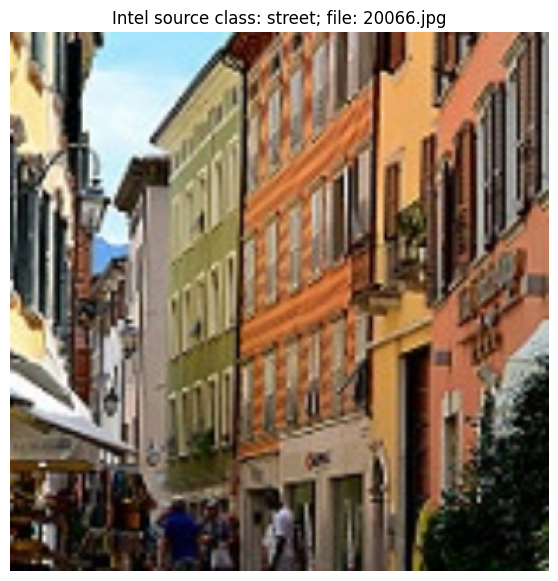

Model 1 — ImageNet-21k
1) 10880 - street; p = 0.3127
2) 10879 - street; p = 0.0786
3) 11410 - tramline, tramway, streetcar_track; p = 0.0404
4) 5125 - building, edifice; p = 0.0343

Model 2 — ImageNet-1k
1) 860 - tobacco shop; p = 0.2221
2) 698 - palace; p = 0.0361
3) 442 - bell cote; p = 0.0237
4) 829 - streetcar; p = 0.0215


In [6]:
# Select an input image from Intel Image Classification.

image_name = 'street'  # buildings, forest, glacier, mountain, sea, street
image_index = 0  # Index within the selected class, sorted by filename.
LOCAL_DATA_DIR = None  # Example: r'D:\data\intel-image-classification'
LOCAL_IMAGE_PATH = None  # Example: '/content/my_photo.jpg'; skips dataset download.

intel_classes = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
if LOCAL_IMAGE_PATH is not None:
    image_path = Path(LOCAL_IMAGE_PATH).expanduser()
    if not image_path.is_file():
        raise FileNotFoundError(f'Image does not exist: {image_path}')
    image_description = image_path.name
else:
    if image_name not in intel_classes:
        raise ValueError(f'Choose one of: {intel_classes}')
    data_root = (Path(LOCAL_DATA_DIR).expanduser() if LOCAL_DATA_DIR is not None
                 else Path(kagglehub.dataset_download('puneet6060/intel-image-classification')))
    candidates = [data_root / 'seg_test', data_root / 'seg_test' / 'seg_test']
    candidates += sorted(data_root.rglob('seg_test'))
    test_dir = next((p for p in candidates if p.is_dir()
                     and all((p / name).is_dir() for name in intel_classes)), None)
    if test_dir is None:
        raise FileNotFoundError(f'Cannot find seg_test with six class folders in {data_root}.')
    image_files = sorted(p for p in (test_dir / image_name).iterdir()
                         if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
    if not 0 <= image_index < len(image_files):
        raise ValueError(f'image_index must be between 0 and {len(image_files) - 1}.')
    image_path = image_files[image_index]
    image_description = f'Intel source class: {image_name}; file: {image_path.name}'

print(image_description)
image, original_image = load_image(image_path, input_size)
show_image(image, image_description)

model_answer = run_model_on_image(image, classifier, classes)
model_answer2 = run_model_on_image(image, classifier2, classes2)
print('Model 1 — ImageNet-21k\n' + model_answer)
print('\nModel 2 — ImageNet-1k\n' + model_answer2)

<br><br>
---

## Let's cut a piece out of the photo and try again

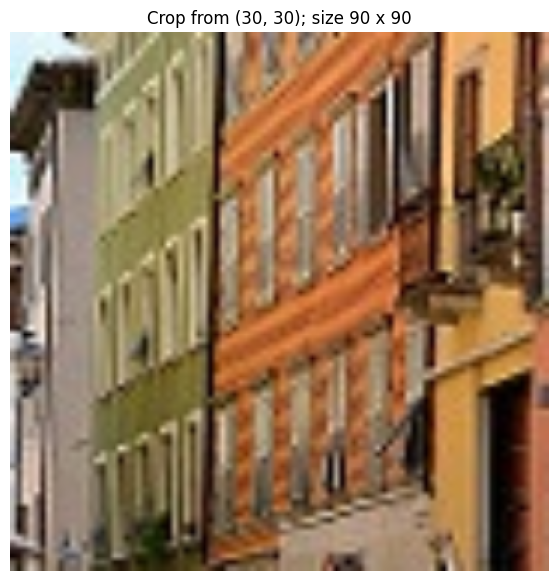

Model 1 — ImageNet-21k
1) 10880 - street; p = 0.1005
2) 5125 - building, edifice; p = 0.0886
3) 11410 - tramline, tramway, streetcar_track; p = 0.0590
4) 10879 - street; p = 0.0301

Model 2 — ImageNet-1k
1) 743 - prison; p = 0.0892
2) 860 - tobacco shop; p = 0.0517
3) 698 - palace; p = 0.0407
4) 675 - moving van; p = 0.0300


In [7]:
# Crop the source photo and run the same two classifiers again.
# Coordinates mark the TOP-LEFT corner. Values are percentages of the source image.
x = 20
y = 20
crop_size_percent = 60  # Percentage of the shorter source-image side.

def crop_bounds(width, height, x_percent, y_percent, size_percent):
    if not (0 <= x_percent < 100 and 0 <= y_percent < 100):
        raise ValueError('Crop coordinates must be at least 0 and less than 100 percent.')
    if not 0 < size_percent <= 100:
        raise ValueError('crop_size_percent must be greater than 0 and at most 100.')
    left = int(width * x_percent / 100)
    top = int(height * y_percent / 100)
    side = max(1, int(min(width, height) * size_percent / 100))
    right = min(width, left + side)
    bottom = min(height, top + side)
    return left, top, right, bottom

height, width = int(original_image.shape[1]), int(original_image.shape[2])
x_cord, y_cord, right, bottom = crop_bounds(width, height, x, y, crop_size_percent)
image_cut = original_image[:, y_cord:bottom, x_cord:right, :]
image = tf.image.resize_with_pad(image_cut, input_size, input_size)

show_image(image, f'Crop from ({x_cord}, {y_cord}); size {right - x_cord} x {bottom - y_cord}')
model_answer = run_model_on_image(image, classifier, classes)
model_answer2 = run_model_on_image(image, classifier2, classes2)
print('Model 1 — ImageNet-21k\n' + model_answer)
print('\nModel 2 — ImageNet-1k\n' + model_answer2)



<br><br>

---
#<font color='SeaGreen'>Chapter 2. Object Detection</font>


In [8]:
# Load the same pretrained detector as in the original notebook.
detector = hub.load('https://tfhub.dev/google/openimages_v4/ssd/mobilenet_v2/1').signatures['default']
# The detector returns detection_class_entities, so no separate label CSV is needed.

In [9]:
#@title Helper functions (hidden)

def display_image(image):
  fig = plt.figure(figsize=(20, 15))
  plt.grid(False)
  plt.imshow(image)


def draw_bounding_box_on_image(image,
                               ymin,
                               xmin,
                               ymax,
                               xmax,
                               color,
                               font,
                               thickness=4,
                               display_str_list=()):
  """Adds a bounding box to an image."""
  draw = ImageDraw.Draw(image)
  im_width, im_height = image.size
  (left, right, top, bottom) = (xmin * im_width, xmax * im_width,
                                ymin * im_height, ymax * im_height)
  draw.line([(left, top), (left, bottom), (right, bottom), (right, top),
             (left, top)],
            width=thickness,
            fill=color)

  # If the total height of the display strings added to the top of the bounding
  # box exceeds the top of the image, stack the strings below the bounding box
  # instead of above.
  display_str_heights = [font.getbbox(ds)[3] for ds in display_str_list]
  # Each display_str has a top and bottom margin of 0.05x.
  total_display_str_height = (1 + 2 * 0.05) * sum(display_str_heights)

  if top > total_display_str_height:
    text_bottom = top
  else:
    text_bottom = top + total_display_str_height
  # Reverse list and print from bottom to top.
  for display_str in display_str_list[::-1]:
    bbox = font.getbbox(display_str)
    text_width, text_height = bbox[2], bbox[3]
    margin = np.ceil(0.05 * text_height)
    draw.rectangle([(left, text_bottom - text_height - 2 * margin),
                    (left + text_width, text_bottom)],
                   fill=color)
    draw.text((left + margin, text_bottom - text_height - margin),
              display_str,
              fill="black",
              font=font)
    text_bottom -= text_height - 2 * margin


def draw_boxes(image, boxes, class_names, scores, max_boxes=10, min_score=0.1):
  """Overlay labeled boxes on an image with formatted scores and label names."""
  colors = list(ImageColor.colormap.values())

  try:
    font = ImageFont.truetype("/usr/share/fonts/truetype/liberation/LiberationSansNarrow-Regular.ttf",
                              25)
  except IOError:
    print("Font not found, using default font.")
    font = ImageFont.load_default()

  for i in range(min(boxes.shape[0], max_boxes)):
    if scores[i] >= min_score:
      ymin, xmin, ymax, xmax = tuple(boxes[i])
      display_str = "{}: {}%".format(class_names[i].decode("ascii"),
                                     int(100 * scores[i]))
      color = colors[hash(class_names[i]) % len(colors)]
      image_pil = Image.fromarray(np.uint8(image)).convert("RGB")
      draw_bounding_box_on_image(
          image_pil,
          ymin,
          xmin,
          ymax,
          xmax,
          color,
          font,
          display_str_list=[display_str])
      np.copyto(image, np.array(image_pil))
  return image



def run_detector_2(detector, p_img, min_score=0.25):
    result = {key: value.numpy() for key, value in detector(p_img).items()}
    count = int(np.count_nonzero(result['detection_scores'] >= min_score))
    print(f'Found {count} detections with score >= {min_score:.2f}; displaying at most 20.')
    image_uint8 = np.clip(np.asarray(p_img)[0] * 255, 0, 255).astype(np.uint8)
    image_with_boxes = draw_boxes(
        image_uint8, result['detection_boxes'], result['detection_class_entities'],
        result['detection_scores'], max_boxes=20, min_score=min_score,
    )
    display_image(image_with_boxes)
    plt.axis('off')
    plt.show()
    return result

>## Detector

Found 0 detections with score >= 0.25; displaying at most 20.
Font not found, using default font.


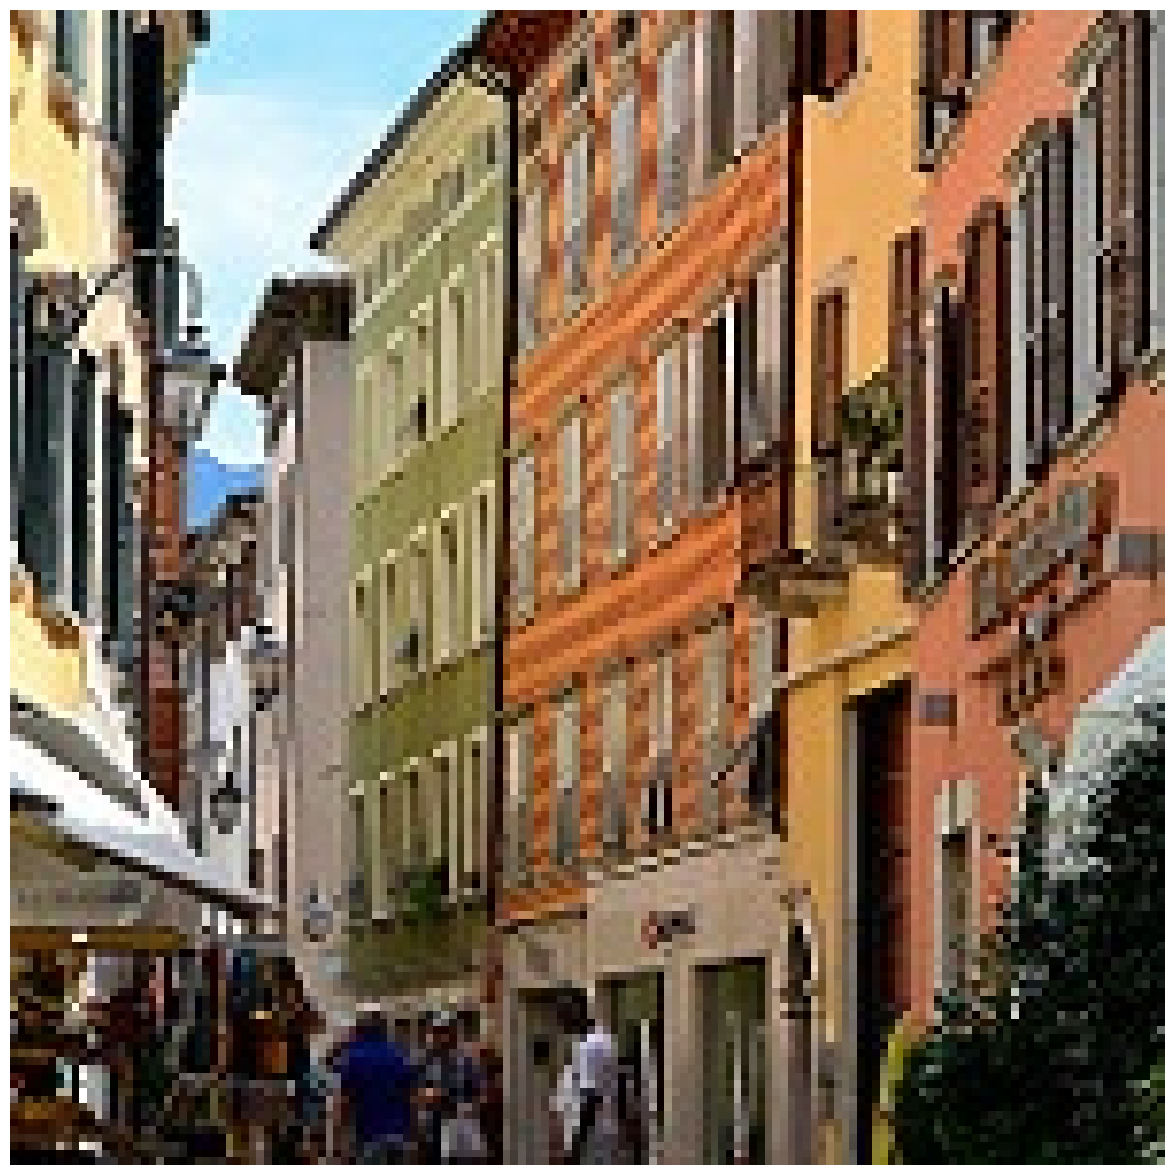

In [10]:
# Detect objects in the complete source image.
detector_output_full = run_detector_2(detector, original_image)

Found 0 detections with score >= 0.25; displaying at most 20.
Font not found, using default font.


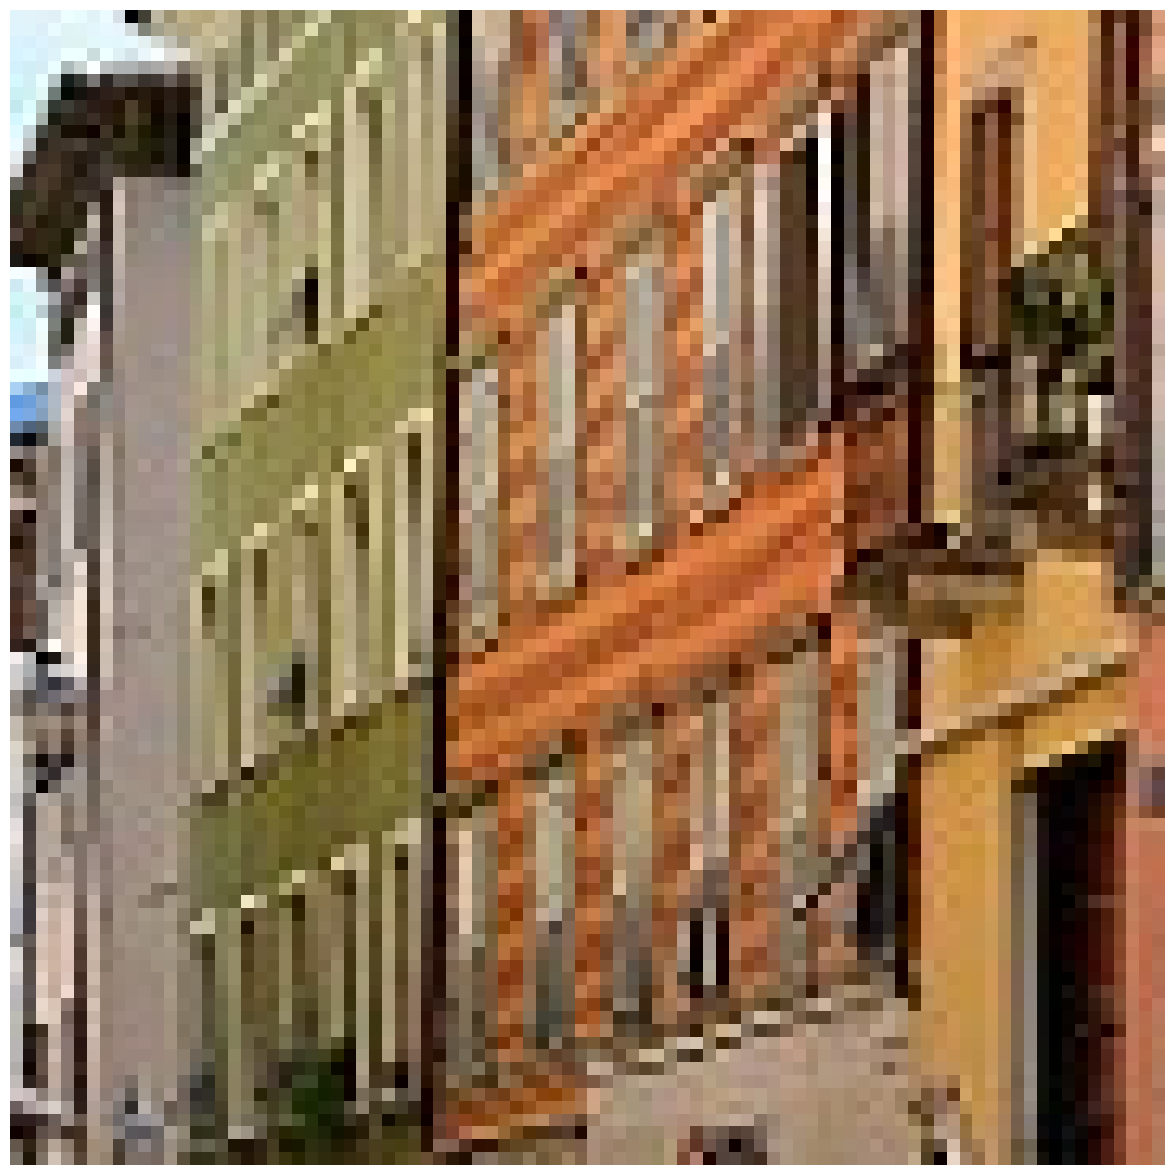

In [11]:
# Detect objects in the crop without classification padding.
detector_output_crop = run_detector_2(detector, image_cut)


<br><br>

---
#<font color='SeaGreen'>Chapter 3. Image segmentation</font>

In [12]:
# Load the same segmentation model as in the original notebook.
segmentation_ade20k_model = hub.load('https://tfhub.dev/google/HRNet/ade20k-hrnetv2-w48/1')

In [13]:
segmentation_labels_path = tf.keras.utils.get_file(
    'ade20k-id2label.json',
    'https://huggingface.co/datasets/huggingface/label-files/raw/main/ade20k-id2label.json',
)
with open(segmentation_labels_path, encoding='utf-8') as f:
    segmentation_label_map = json.load(f)
ade20k_labels = [segmentation_label_map[str(i)] for i in range(len(segmentation_label_map))]

2814/2814 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


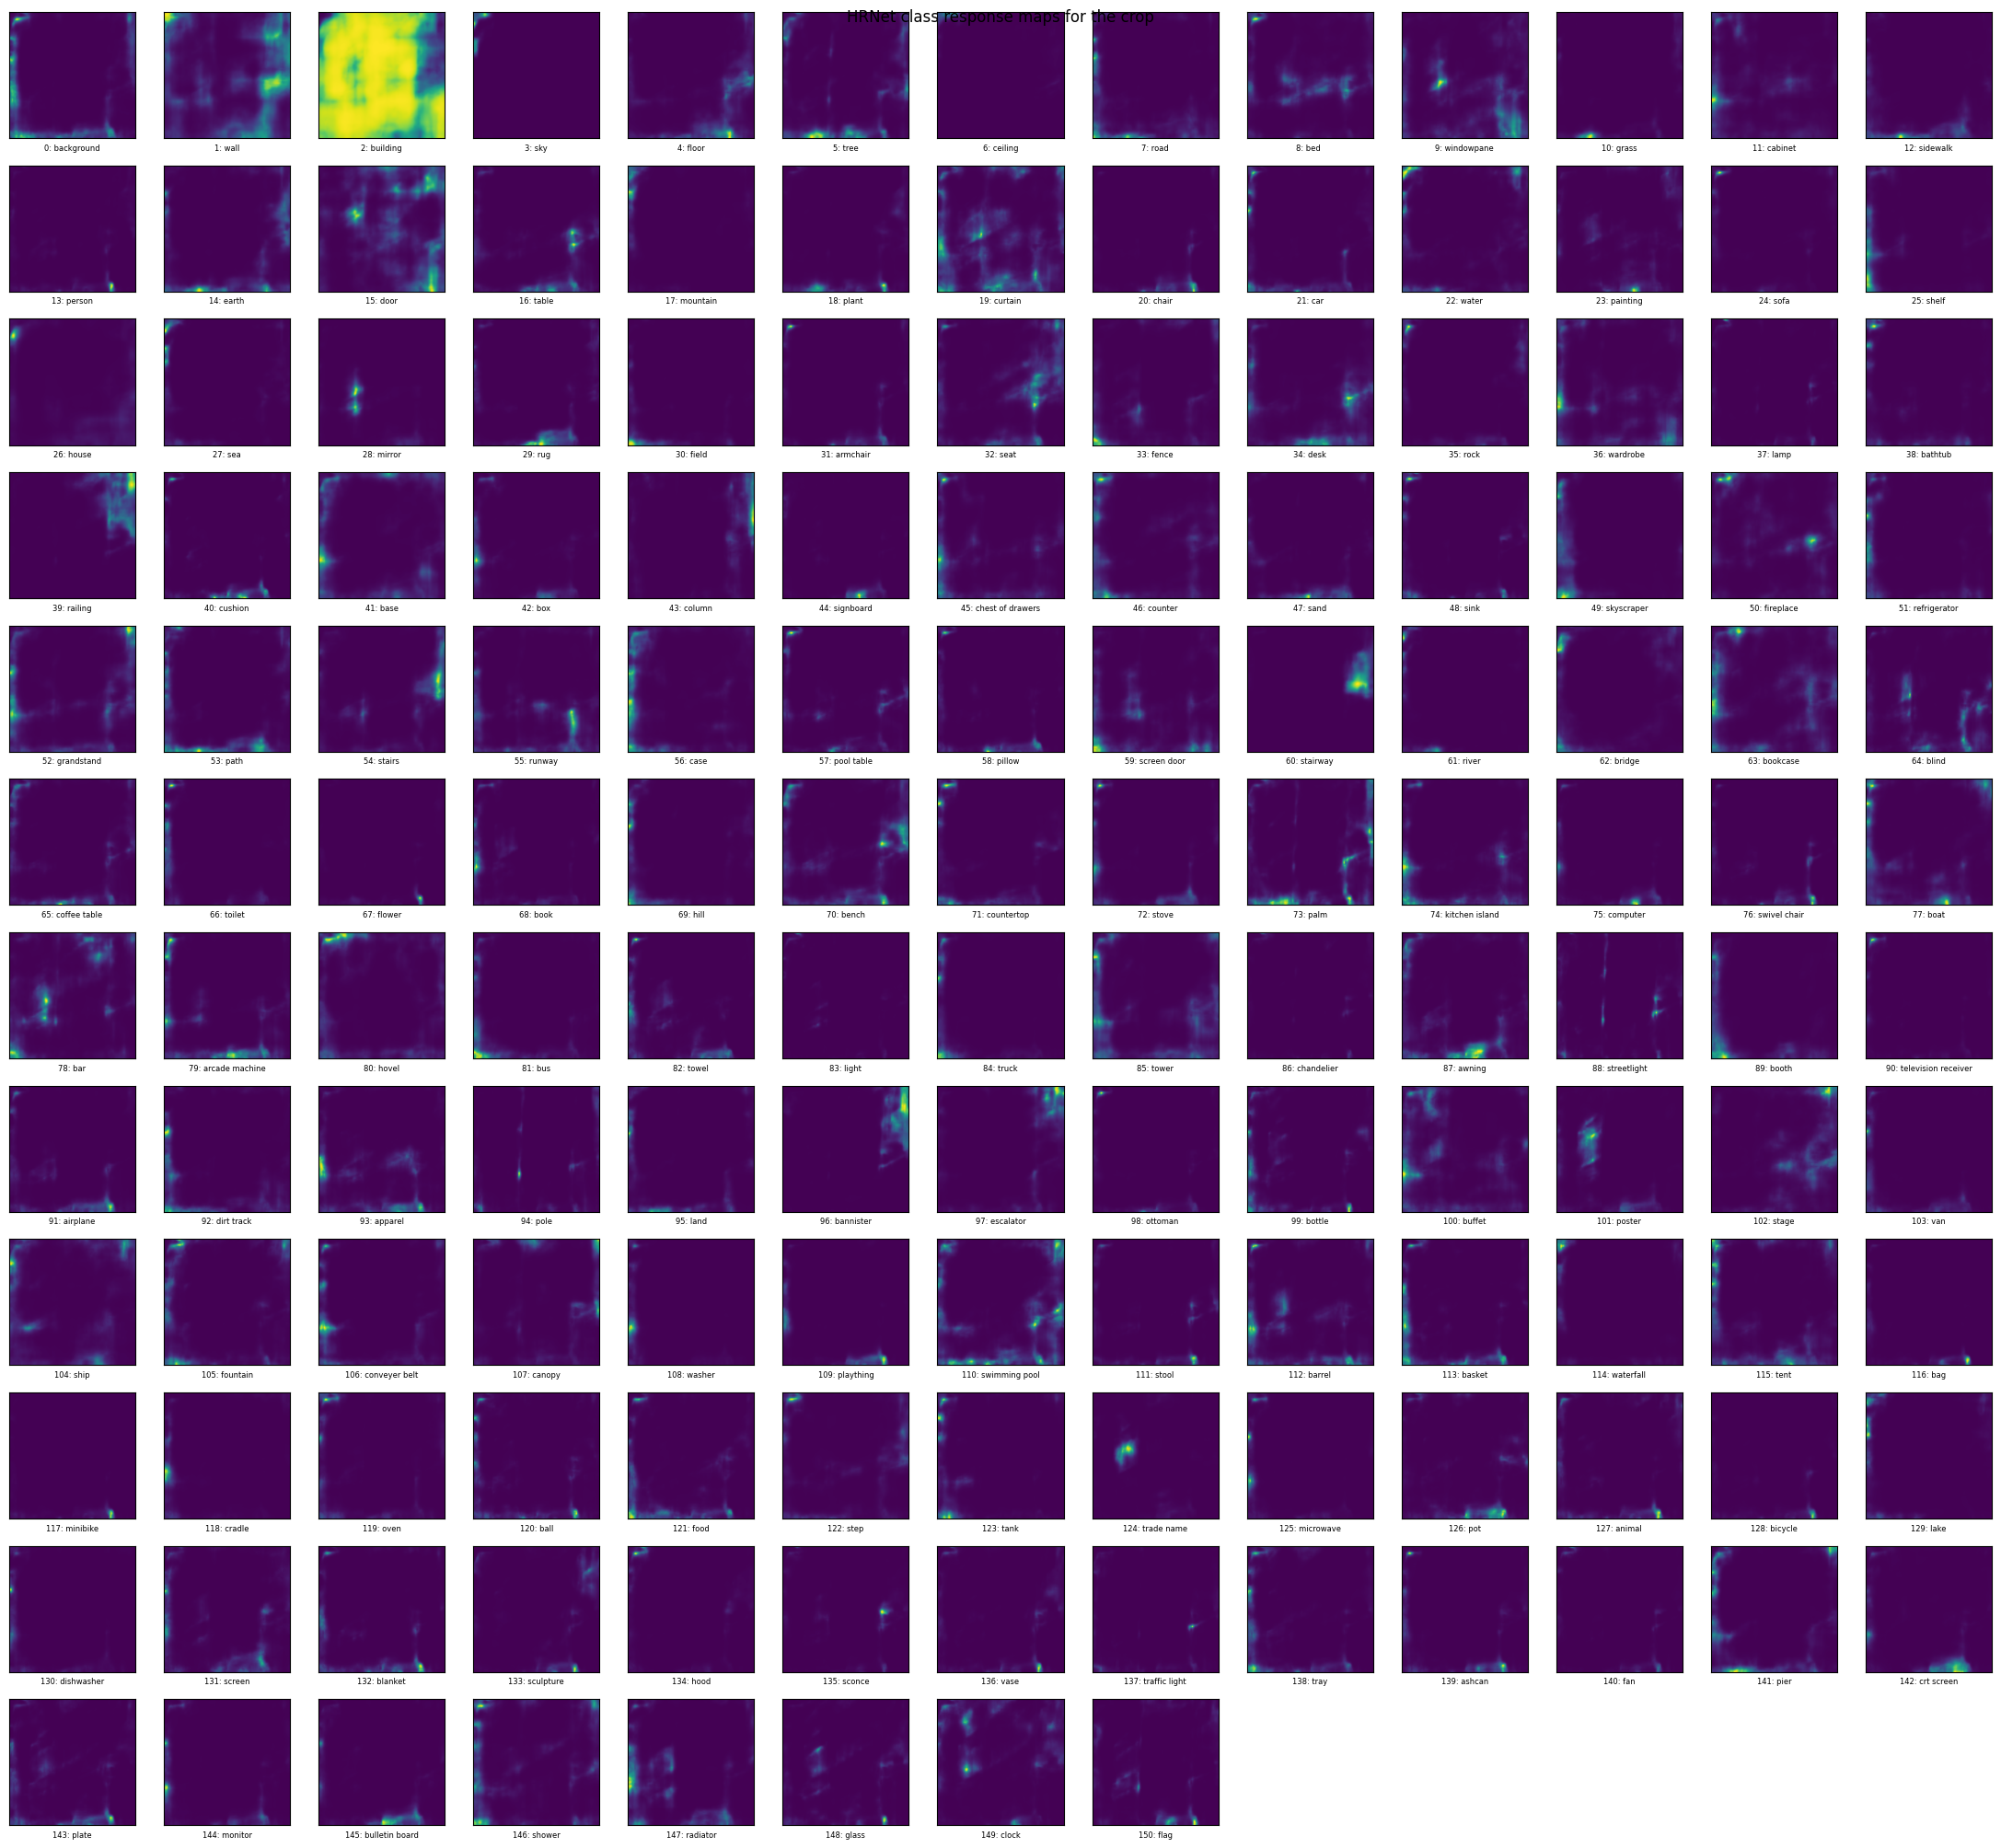

In [14]:
import math

# Segment the resized crop, as in the original workflow.
predictions = np.asarray(segmentation_ade20k_model.predict(image))[0]
if predictions.ndim != 3:
    raise ValueError(f'Expected height x width x classes, got {predictions.shape}.')
number_of_masks = predictions.shape[-1]
if number_of_masks == len(ade20k_labels) + 1:
    classes_segmentation = ['background'] + ade20k_labels
elif number_of_masks == len(ade20k_labels):
    classes_segmentation = ade20k_labels
else:
    raise ValueError(f'The model has {number_of_masks} channels, but the ADE20K label file '
                     f'has {len(ade20k_labels)} labels. Check the model/label mapping.')

plot_dim = math.ceil(math.sqrt(number_of_masks))
plt.figure(figsize=(22, 22))
for i in range(number_of_masks):
    plt.subplot(plot_dim, plot_dim, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(predictions[:, :, i])
    plt.xlabel(f'{i}: {classes_segmentation[i]}', fontsize=6)
plt.suptitle('HRNet class response maps for the crop')
plt.tight_layout()
plt.show()

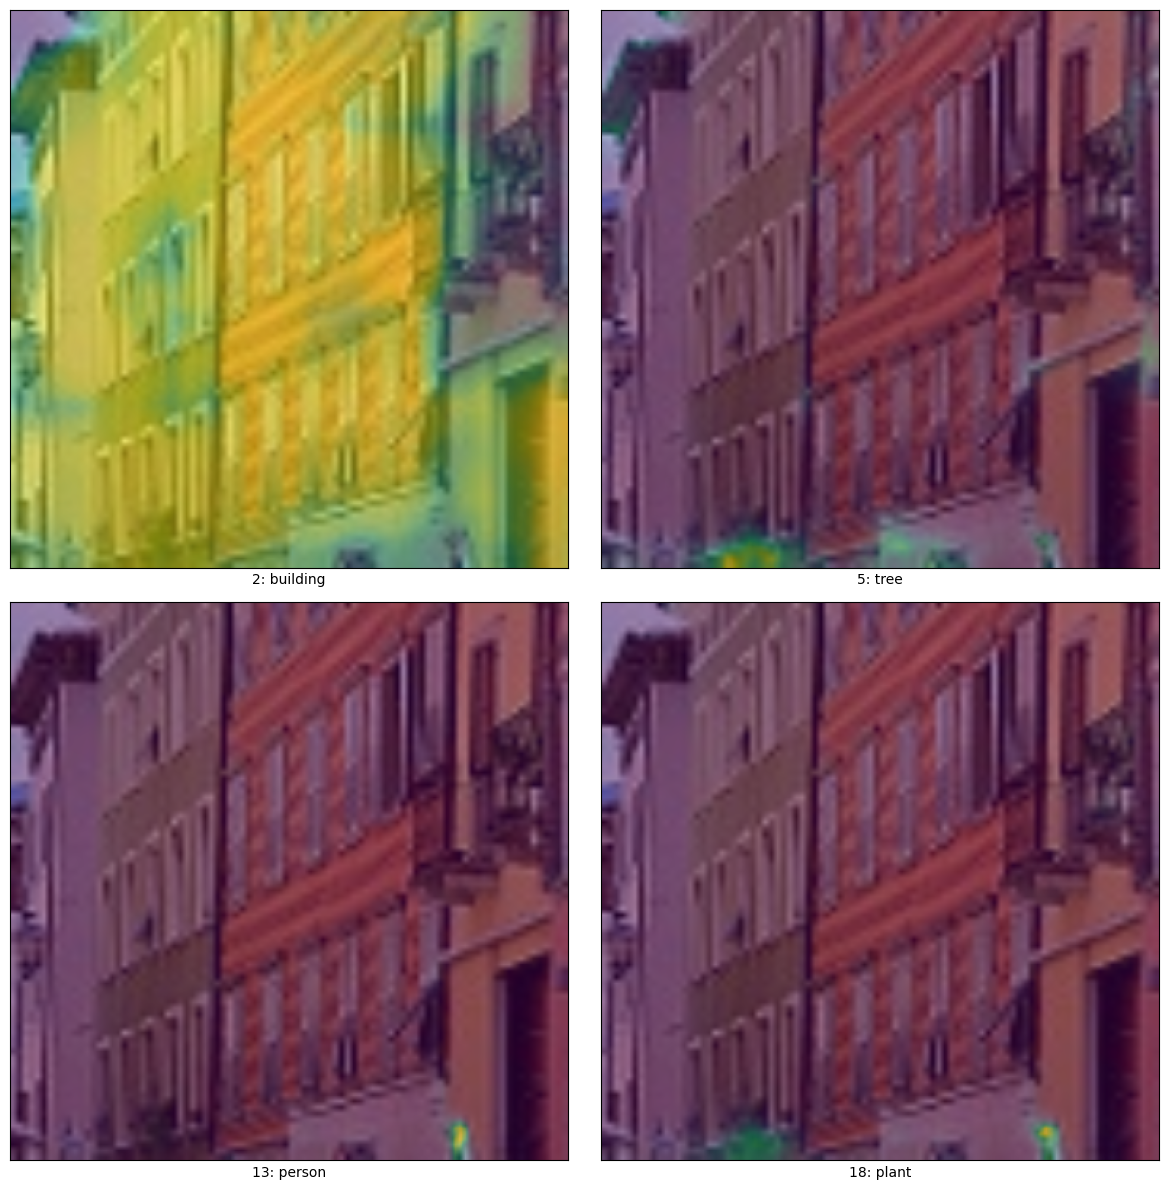

In [15]:
# Display four class-response overlays. Select valid channel IDs from the grid above.
mask_indices = [2, 5, 13, 18]
if any(i < 0 or i >= number_of_masks for i in mask_indices):
    raise ValueError(f'Mask indices must be between 0 and {number_of_masks - 1}.')

# Align the image with the response maps before overlaying them.
overlay_image = tf.image.resize(image[0], predictions.shape[:2]).numpy()
plt.figure(figsize=(12, 12))
for i, channel in enumerate(mask_indices):
    plt.subplot(2, 2, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(np.clip(overlay_image, 0, 1))
    plt.imshow(predictions[:, :, channel], alpha=0.5)
    plt.xlabel(f'{channel}: {classes_segmentation[channel]}')
plt.tight_layout()
plt.show()